### Importando as Bibliotecas

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)

def drop_reset_index(df):
    df = df.dropna()
    df = df.reset_index(drop=True)
    df.index += 1
    return df

def plot_profit_acu(dataframe, title_text):
    dataframe['Profit_acu'] = dataframe.Profit.cumsum()
    n_apostas = dataframe.shape[0]
    profit = round(dataframe.Profit_acu.tail(1).item(), 2)
    # ROI = round((dataframe.Profit_acu.tail(1) / n_apostas * 100).item(), 2)
    dataframe['Investimento_acu'] = dataframe.Investimento.cumsum()
    ROI = round(((dataframe.Profit_acu.tail(1) / dataframe.Investimento_acu.tail(1)) * 100).item(), 2)
    drawdown = dataframe['Profit_acu'] - dataframe['Profit_acu'].cummax()
    drawdown_maximo = round(drawdown.min(), 2)
    winrate_medio = round((dataframe['Profit'] > 0).mean() * 100, 2)
    desvio_padrao = round(dataframe['Profit'].std(), 2)
    dataframe.Profit_acu.plot(title=title_text, xlabel='Entradas', ylabel='Stakes')
    print("Metodo:",title_text)
    print("Profit:", profit, "stakes em", n_apostas, "jogos")
    print("ROI:", ROI, "%")
    print("Drawdown Maximo Acumulado:", drawdown_maximo)
    print("Winrate Medio:", winrate_medio, "%")
    print("Desvio Padrao:", desvio_padrao)
    print("")

In [2]:
def rename_leagues(df):
    df.replace('Argentinian Copa de la Liga Profesional','ARGENTINA - COPA DE LA LIGA PROFESIONAL', inplace=True)
    df.replace('Argentinian Primera Division','ARGENTINA - LIGA PROFESIONAL', inplace=True)
    df.replace('Armenian Premier League','ARMENIA - PREMIER LEAGUE', inplace=True)
    df.replace('Australian A-League Men','AUSTRALIA - A-LEAGUE', inplace=True)
    df.replace('Austrian Bundesliga','AUSTRIA - 2. LIGA', inplace=True)
    df.replace('Austrian Erste Liga','AUSTRIA - BUNDESLIGA', inplace=True)
    df.replace('Belgian First Division B','BELGIUM - CHALLENGER PRO LEAGUE', inplace=True)
    df.replace('Belgian First Division A','BELGIUM - JUPILER PRO LEAGUE', inplace=True)
    df.replace('Bolivian Liga de Futbol Profesional','BOLIVIA - DIVISION PROFESIONAL', inplace=True)
    df.replace('Bosnian Premier League','BOSNIA AND HERZEGOVINA - PREMIJER LIGA BIH', inplace=True)
    df.replace('Brazilian Serie A','BRAZIL - SERIE A', inplace=True)
    df.replace('Brazilian Serie B','BRAZIL - SERIE B', inplace=True)
    df.replace('Brazilian Serie C','BRAZIL - SERIE C', inplace=True)
    df.replace('Brazilian Serie D','BRAZIL - SERIE D', inplace=True)
    df.replace('Bulgarian A League','BULGARIA - PARVA LIGA', inplace=True)
    df.replace('Chilean Primera Division','CHILE - PRIMERA DIVISION', inplace=True)
    df.replace('Chinese Super League','CHINA - SUPER LEAGUE', inplace=True)
    df.replace('Colombian Primera A','COLOMBIA - PRIMERA A', inplace=True)
    df.replace('Croatian 1 HNL','CROATIA - HNL', inplace=True)
    df.replace('Croatian 2 HNL','CROATIA - PRVA NL', inplace=True)
    df.replace('Cypriot 1st Division','CYPRUS - CYTA CHAMPIONSHIP', inplace=True)
    df.replace('Czech 1 Liga','CZECH REPUBLIC - FORTUNA LIGA', inplace=True)
    df.replace('Danish 1st Division','DENMARK - 1ST DIVISION', inplace=True)
    df.replace('Danish Superliga','DENMARK - SUPERLIGA', inplace=True)
    df.replace('Ecuadorian Serie A','ECUADOR - LIGA PRO', inplace=True)
    df.replace('Egyptian Premier','EGYPT - PREMIER LEAGUE', inplace=True)
    df.replace('English Championship','ENGLAND - CHAMPIONSHIP', inplace=True)
    df.replace('English League 1','ENGLAND - LEAGUE ONE', inplace=True)
    df.replace('English League 2','ENGLAND - LEAGUE TWO', inplace=True)
    df.replace('English National League','ENGLAND - NATIONAL LEAGUE', inplace=True)
    df.replace('English Premier League','ENGLAND - PREMIER LEAGUE', inplace=True)
    df.replace('Estonian Esiliiga','ESTONIA - ESILIIGA', inplace=True)
    df.replace('Estonian Premier League','ESTONIA - MEISTRILIIGA', inplace=True)
    df.replace('UEFA Champions League','EUROPE - CHAMPIONS LEAGUE', inplace=True)
    df.replace('UEFA Europa Conference League','EUROPE - EUROPA CONFERENCE LEAG', inplace=True)
    df.replace('UEFA Europa League','EUROPE - EUROPA LEAGUE', inplace=True)
    df.replace('Finnish Veikkausliiga','FINLAND - VEIKKAUSLIIGA', inplace=True)
    df.replace('Finnish Ykkonen','FINLAND - YKKONEN', inplace=True)
    df.replace('French Ligue 1','FRANCE - LIGUE 1', inplace=True)
    df.replace('French Ligue 2','FRANCE - LIGUE 2', inplace=True)
    df.replace('French National','FRANCE - NATIONAL', inplace=True)
    df.replace('German Bundesliga 2','GERMANY - 2. BUNDESLIGA', inplace=True)
    df.replace('German 3 Liga','GERMANY - 3. LIGA', inplace=True)
    df.replace('German Bundesliga','GERMANY - BUNDESLIGA', inplace=True)
    df.replace('Greek Super League','GREECE - SUPER LEAGUE', inplace=True)
    df.replace('Hungarian NB I','HUNGARY - OTP BANK LIGA', inplace=True)
    #df.replace('????','ICELAND - BESTA DEILD KARLA', inplace=True)
    df.replace('Icelandic 1 Deild','ICELAND - LENGJUDEILDIN', inplace=True)
    df.replace('Irish Division 1','IRELAND - DIVISION 1', inplace=True)
    df.replace('Irish Premier Division','IRELAND - PREMIER DIVISION', inplace=True)
    df.replace('Israeli Premier League',"ISRAEL - LIGAT HA'AL", inplace=True)
    df.replace('Italian Serie A','ITALY - SERIE A', inplace=True)
    df.replace('Italian Serie B','ITALY - SERIE B', inplace=True)
    df.replace('Italian Serie C','ITALY - SERIE C', inplace=True)
    df.replace('Italian Serie D','ITALY - SERIE D', inplace=True)
    df.replace('Japanese J League','JAPAN - J1 LEAGUE', inplace=True)
    df.replace('Japanese J League 2','JAPAN - J2 LEAGUE', inplace=True)
    df.replace('Mexican Liga MX','MEXICO - LIGA MX', inplace=True)
    df.replace('Dutch Eerste Divisie','NETHERLANDS - EERSTE DIVISIE', inplace=True)
    df.replace('Dutch Eredivisie','NETHERLANDS - EREDIVISIE', inplace=True)
    df.replace('Northern Irish Championship','NORTHERN IRELAND - NIFL CHAMPIO', inplace=True)
    df.replace('Northern Irish Premiership','NORTHERN IRELAND - NIFL PREMIER', inplace=True)
    df.replace('Norwegian Eliteserien','NORWAY - ELITESERIEN', inplace=True)
    df.replace('Norwegian 1st Division','NORWAY - OBOS-LIGAEN', inplace=True)
    df.replace('Paraguayan Primera Division','PARAGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('Peruvian Primera Division','PERU - LIGA 1', inplace=True)
    df.replace('Polish I Liga','POLAND - DIVISION 1', inplace=True)
    df.replace('Polish Ekstraklasa','POLAND - EKSTRAKLASA', inplace=True)
    df.replace('Portuguese Primeira Liga','PORTUGAL - LIGA PORTUGAL', inplace=True)
    df.replace('Portuguese Segunda Liga','PORTUGAL - LIGA PORTUGAL 2', inplace=True)
    df.replace('Romanian Liga I','ROMANIA - LIGA 1', inplace=True)
    df.replace('Romanian Liga II','ROMANIA - LIGA 2', inplace=True)
    df.replace('Saudi Professional League','SAUDI ARABIA - SAUDI PROFESSION', inplace=True)
    df.replace('Scottish Championship','SCOTLAND - CHAMPIONSHIP', inplace=True)
    df.replace('Scottish League One','SCOTLAND - LEAGUE ONE', inplace=True)
    df.replace('Scottish League Two','SCOTLAND - LEAGUE TWO', inplace=True)
    df.replace('Scottish Premiership','SCOTLAND - PREMIERSHIP', inplace=True)
    df.replace('Serbian First League','SERBIA - PRVA LIGA', inplace=True)
    df.replace('Serbian Super League','SERBIA - SUPER LIGA', inplace=True)
    df.replace('Slovakian Super League','SLOVAKIA - NIKE LIGA', inplace=True)
    df.replace('Slovenian Premier League','SLOVENIA - PRVA LIGA', inplace=True)
    df.replace('South African Premier Division','SOUTH AFRICA - PREMIER LEAGUE', inplace=True)
    df.replace('CONMEBOL Copa Libertadores','SOUTH AMERICA - COPA LIBERTADOR', inplace=True)
    df.replace('CONMEBOL Copa Sudamericana','SOUTH AMERICA - COPA SUDAMERICA', inplace=True)
    df.replace('South Korean K League 1','SOUTH KOREA - K LEAGUE 1', inplace=True)
    df.replace('South Korean K League 2','SOUTH KOREA - K LEAGUE 2', inplace=True)
    df.replace('Spanish La Liga','SPAIN - LALIGA', inplace=True)
    df.replace('Spanish Segunda Division','SPAIN - LALIGA2', inplace=True)
    df.replace('Spanish Primera Division RFEF A','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF B','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF C','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF D','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF E','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF F','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Primera Division RFEF G','SPAIN - PRIMERA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 1','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 2','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 3','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 4','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Spanish Segunda RFEF - Group 5','SPAIN - SEGUNDA RFEF', inplace=True)
    df.replace('Swedish Allsvenskan','SWEDEN - ALLSVENSKAN', inplace=True)
    df.replace('Swedish Superettan','SWEDEN - SUPERETTAN', inplace=True)
    df.replace('Swiss Challenge League','SWITZERLAND - CHALLENGE LEAGUE', inplace=True)
    df.replace('Swiss Super League','SWITZERLAND - SUPER LEAGUE', inplace=True)
    df.replace('Todas as Ligas','Todas as Ligas', inplace=True)
    df.replace('Turkish 1 Lig','TURKEY - 1. LIG', inplace=True)
    df.replace('Turkish Super League','TURKEY - SUPER LIG', inplace=True)
    df.replace('Ukrainian Premier League','UKRAINE - PREMIER LEAGUE', inplace=True)
    df.replace('Uruguayan Primera Division','URUGUAY - PRIMERA DIVISION', inplace=True)
    df.replace('US Major League Soccer','USA - MLS', inplace=True)
    df.replace('US MLS','USA - MLS', inplace=True)
    df.replace('Venezuelan Primera Division','VENEZUELA - LIGA FUTVE', inplace=True)
    df.replace('Welsh Premiership','WALES - CYMRU PREMIER', inplace=True)

### Importando a Base de Dados

In [3]:
base = pd.read_csv("https://github.com/futpythontrader/YouTube/raw/main/Bases_de_Dados/Betfair/Base_de_Dados_Betfair_Exchange_Back_Lay.csv")
base = base[['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
             'Odd_H_Back','Odd_H_Lay','Odd_A_Back','Odd_A_Lay','Odd_D_Back','Odd_D_Lay',
             'Odd_Over25_FT_Back','Odd_Under25_FT_Back','Odd_BTTS_Yes_Back','Odd_BTTS_No_Back',
             'Odd_CS_0x0_Lay','Odd_CS_0x1_Lay','Odd_CS_1x0_Lay','Odd_CS_Goleada_H_Lay','Odd_CS_Goleada_A_Lay']]
base.columns = ['Date','League','Home','Away','Goals_H','Goals_A','Goals_Min_H','Goals_Min_A',
                'Odd_H','Odd_H_Lay','Odd_A','Odd_A_Lay','Odd_D','Odd_D_Lay',
                'Odd_Over25','Odd_Under25','Odd_BTTS_Yes','Odd_BTTS_No',
                'Odd_0x0','Odd_0x1','Odd_1x0','Odd_Gol_H','Odd_Gol_A']
base = drop_reset_index(base)

In [4]:
leagues = base.sort_values(by='League')
leagues = leagues['League'].unique()
leagues

array(['ARGENTINA - COPA DE LA LIGA PROFESIONAL',
       'ARGENTINA - LIGA PROFESIONAL', 'ARMENIA - PREMIER LEAGUE',
       'AUSTRALIA - A-LEAGUE', 'BELGIUM - CHALLENGER PRO LEAGUE',
       'BELGIUM - JUPILER PRO LEAGUE', 'BOLIVIA - DIVISION PROFESIONAL',
       'BRAZIL - SERIE A', 'BRAZIL - SERIE B', 'BRAZIL - SERIE C',
       'BRAZIL - SERIE D', 'BULGARIA - PARVA LIGA',
       'CHILE - PRIMERA DIVISION', 'CHINA - SUPER LEAGUE',
       'COLOMBIA - PRIMERA A', 'CROATIA - HNL', 'CROATIA - PRVA NL',
       'DENMARK - 1ST DIVISION', 'DENMARK - SUPERLIGA',
       'ECUADOR - LIGA PRO', 'EGYPT - PREMIER LEAGUE',
       'ENGLAND - CHAMPIONSHIP', 'ENGLAND - LEAGUE ONE',
       'ENGLAND - LEAGUE TWO', 'ENGLAND - NATIONAL LEAGUE',
       'ENGLAND - PREMIER LEAGUE', 'ESTONIA - ESILIIGA',
       'ESTONIA - MEISTRILIIGA', 'EUROPE - CHAMPIONS LEAGUE',
       'EUROPE - EUROPA LEAGUE', 'FINLAND - VEIKKAUSLIIGA',
       'FINLAND - YKKONEN', 'FRANCE - LIGUE 1', 'FRANCE - LIGUE 2',
       'FRANCE - NATIO

### Criação de Variáveis

In [5]:
df = base.copy()

df['VAR01'] = np.abs(df['Odd_H'] - df['Odd_A'])
df['VAR02'] = np.abs(df['Odd_H'] - df['Odd_D'])
df['VAR03'] = np.abs(df['Odd_D'] - df['Odd_A'])
df['VAR04'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_H']) / 2))
df['VAR05'] = np.degrees(np.arctan((df['Odd_D'] - df['Odd_H']) / 2))
df['VAR06'] = np.degrees(np.arctan((df['Odd_A'] - df['Odd_D']) / 2))
df['VAR07'] = np.abs((df['Odd_H'] - df['Odd_A'])) / df['Odd_A']
df['VAR08'] = np.abs((df['Odd_H'] - df['Odd_D'])) / df['Odd_D']
df['VAR09'] = np.abs((df['Odd_D'] - df['Odd_A'])) / df['Odd_A']

In [6]:
# df['Back_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 1, 0)
# df['Profit_Back_Home'] = np.where((df['Back_Home'] == 1), df['Odd_H']-1, -1)

# df['Back_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 1, 0)
# df['Profit_Back_Draw'] = np.where((df['Back_Draw'] == 1), df['Odd_D']-1, -1)

# df['Back_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 1, 0)
# df['Profit_Back_Away'] = np.where((df['Back_Away'] == 1), df['Odd_A']-1, -1)

# df['Lay_Home'] = np.where((df['Goals_H'] >  df['Goals_A']), 0, 1)
# df['Profit_Lay_Home'] = np.where((df['Lay_Home'] == 1), 0.94/(df['Odd_H_Lay']-1), -1)

# df['Lay_Draw'] = np.where((df['Goals_H'] == df['Goals_A']), 0, 1)
# df['Profit_Lay_Draw'] = np.where((df['Lay_Draw'] == 1), 0.94/(df['Odd_D_Lay']-1), -1)

df['Lay_Away'] = np.where((df['Goals_H']  < df['Goals_A']), 0, 1)
df['Profit_Lay_Away'] = np.where((df['Lay_Away'] == 1), 0.94/(df['Odd_A_Lay']-1), -1)

# df['Over25'] = np.where((df['Goals_H'] + df['Goals_A']) > 2, 1, 0)
# df['Profit_Over25'] = np.where((df['Over25'] == 1), df['Odd_Over25']-1, -1)

# df['Under25'] = np.where((df['Goals_H'] + df['Goals_A']) < 3, 1, 0)
# df['Profit_Under25'] = np.where((df['Under25'] == 1), df['Odd_Under25']-1, -1)

# df['BTTS'] = np.where(((df['Goals_H'] > 0) & (df['Goals_A'] > 0)), 1, 0)
# df['Profit_BTTS'] = np.where((df['BTTS'] == 1), df['Odd_BTTS_Yes']-1, -1)

df['Lay_0x1'] = np.where(((df['Goals_H'] == 0) & (df['Goals_A'] == 1)), 0, 1)
df['Profit_Lay_0x1'] = np.where((df['Lay_0x1'] == 1), 1/(df['Odd_0x1']-1), -1)

# df['Lay_1x0'] = np.where(((df['Goals_H'] == 1) & (df['Goals_A'] == 0)), 0, 1)
# df['Profit_Lay_1x0'] = np.where((df['Lay_1x0'] == 1), 1/(df['Odd_1x0']-1), -1)

# df['Lay_Gol_H'] = np.where(((df['Goals_H'] > df['Goals_A']) & (df['Goals_H'] >= 4)), 0, 1)
# df['Profit_Lay_Gol_H'] = np.where((df['Lay_Gol_H'] == 1), 1/(df['Odd_Gol_H']-1), -1)

df['Lay_Gol_A'] = np.where(((df['Goals_A'] > df['Goals_H']) & (df['Goals_A'] >= 4)), 0, 1)
df['Profit_Lay_Gol_A'] = np.where((df['Lay_Gol_A'] == 1), 1/(df['Odd_Gol_A']-1), -1)

In [7]:
metade = len(df) // 2

df_train = df.iloc[:metade]
df_test = df.iloc[metade:]

print(f"Tamanho do dataframe de treino: {len(df_train)}")
print(f"Tamanho do dataframe de teste: {len(df_test)}")

Tamanho do dataframe de treino: 3154
Tamanho do dataframe de teste: 3155


In [8]:
df_train.to_excel("Base_Treino_Variáveis.xlsx", index=False)

### Filtros da Tabela Dinâmica

In [30]:
flt = (df_test.VAR01 < 4.5) & (df_test.VAR04 > 40) & (df_test.Odd_Gol_A <= 100)
df0 = df_test[flt]
df0 = drop_reset_index(df0)
df0

,Date,League,Home,Away,Goals_H,Goals_A,Goals_Min_H,Goals_Min_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Odd_0x0,Odd_0x1,Odd_1x0,Odd_Gol_H,Odd_Gol_A,VAR01,VAR02,VAR03,VAR04,VAR05,VAR06,VAR07,VAR08,VAR09,Lay_Away,Profit_Lay_Away,Lay_0x1,Profit_Lay_0x1,Lay_Gol_A,Profit_Lay_Gol_A
1,2024-04-22,PORTUGAL - LIGA PORTUGAL 2,Nacional,Benfica B,3,1,"[25, 45, 49]",[90],1.79,1.95,3.85,5.9,3.05,5.00,1.80,1.87,1.64,1.92,20.0,22.0,12.0,13.0,70.0,2.06,1.26,0.80,45.846674,32.210928,21.801409,0.535065,0.413115,0.207792,1,0.191837,1,0.047619,1,0.014493
2,2024-04-22,BOLIVIA - DIVISION PROFESIONAL,SA Bulo Bulo,Independiente,6,1,"[7, 13, 36, 51, 81, 90]",[41],1.75,1.84,4.80,5.5,3.80,4.40,1.89,2.02,1.82,2.04,17.0,20.0,9.6,11.0,75.0,3.05,2.05,1.00,56.745633,45.707319,26.565051,0.635417,0.539474,0.208333,1,0.208889,1,0.052632,1,0.013514
3,2024-04-23,SWEDEN - SUPERETTAN,Degerfors,Helsingborg,2,1,"[29, 60]",[41],1.97,2.00,4.10,4.6,3.60,3.80,1.95,1.98,1.83,2.08,14.0,16.0,9.4,14.0,60.0,2.13,1.63,0.50,46.802904,39.180034,14.036243,0.519512,0.452778,0.121951,1,0.261111,1,0.066667,1,0.016949
4,2024-04-23,FRANCE - LIGUE 2,Bastia,Concarneau,2,0,"[52, 90]",[],2.18,2.22,3.95,4.1,3.30,3.35,2.44,1.64,2.02,1.83,9.6,12.0,7.8,25.0,75.0,1.77,1.12,0.65,41.508829,29.248826,18.004162,0.448101,0.339394,0.164557,1,0.303226,1,0.090909,1,0.013514
5,2024-04-23,FRANCE - LIGUE 2,Bordeaux,Dunkerque,2,0,"[38, 46]",[],1.77,1.79,5.60,5.8,3.75,3.80,1.90,2.04,1.85,2.06,14.5,19.5,9.2,11.0,80.0,3.83,1.98,1.85,62.426742,44.712084,42.768825,0.683929,0.528000,0.330357,1,0.195833,1,0.054054,1,0.012658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
366,2024-06-03,IRELAND - PREMIER DIVISION,St. Patricks,Dundalk,2,3,"[27, 35]","[2, 4, 22]",2.00,2.06,4.30,4.6,3.50,3.55,2.24,1.77,2.00,1.92,11.5,14.0,8.0,17.5,80.0,2.30,1.50,0.80,48.990913,36.869898,21.801409,0.534884,0.428571,0.186047,0,-1.000000,1,0.076923,1,0.012658
367,2024-06-05,BRAZIL - SERIE A,Cuiaba,Vitoria,0,0,[],[],2.26,2.30,4.00,4.2,3.15,3.20,2.76,1.54,2.24,1.75,8.2,11.0,7.0,32.0,100.0,1.74,0.89,0.85,41.023269,23.989064,23.025492,0.435000,0.282540,0.212500,1,0.293750,1,0.100000,1,0.010101
368,2024-06-07,FINLAND - VEIKKAUSLIIGA,Haka,Mariehamn,2,0,"[23, 53]",[],1.94,1.96,4.10,4.4,3.90,4.00,1.81,2.02,1.75,2.18,16.5,16.5,10.5,12.5,60.0,2.16,1.96,0.20,47.202598,44.421274,5.710593,0.526829,0.502564,0.048780,1,0.276471,1,0.064516,1,0.016949
369,2024-06-07,FINLAND - VEIKKAUSLIIGA,HJK,SJK,4,1,"[33, 78, 83, 90]",[5],2.00,2.02,4.10,4.3,3.75,3.85,1.94,2.04,1.83,2.14,15.0,16.0,9.6,14.0,55.0,2.10,1.75,0.35,46.397181,41.185925,9.926246,0.512195,0.466667,0.085366,1,0.284848,1,0.066667,1,0.018519


In [27]:
df0['Profit'] = df0['Profit_Lay_Gol_A']
df0['Investimento'] = 1
df0['Profit_Acu'] = df0['Profit'].cumsum()
df0[['Profit_Acu']].tail(1)

,Profit_Acu
370,-12.85402


In [28]:
df0.describe()

,Goals_H,Goals_A,Odd_H,Odd_H_Lay,Odd_A,Odd_A_Lay,Odd_D,Odd_D_Lay,Odd_Over25,Odd_Under25,Odd_BTTS_Yes,Odd_BTTS_No,Odd_0x0,Odd_0x1,Odd_1x0,Odd_Gol_H,Odd_Gol_A,VAR01,VAR02,VAR03,VAR04,VAR05,VAR06,VAR07,VAR08,VAR09,Lay_Away,Profit_Lay_Away,Lay_0x1,Profit_Lay_0x1,Lay_Gol_A,Profit_Lay_Gol_A,Profit,Investimento,Profit_Acu
count,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.000000,370.0,370.000000
mean,1.900000,1.078378,1.857514,1.910270,4.544459,7.648243,3.957000,6.752432,1.819973,2.230135,1.686270,2.133000,34.215946,38.389189,24.126757,12.261081,56.070270,2.686946,2.099486,0.640973,52.009241,45.195917,15.581949,0.580256,0.520465,0.135427,0.800000,-0.003161,0.962162,-0.026746,0.983784,-0.034741,-0.034741,1.0,-1.755428
std,1.400058,0.983229,0.171043,0.180484,0.617377,51.746510,0.458648,48.652358,0.268772,0.434434,0.369405,0.511384,122.270055,131.135849,112.095626,7.678298,23.439866,0.763052,0.603943,0.428198,7.407269,8.251320,12.721392,0.085336,0.093052,0.080382,0.400542,0.500761,0.191062,0.279310,0.126477,0.231225,0.231225,0.0,3.511157
min,0.000000,0.000000,1.380000,1.440000,3.350000,3.800000,2.940000,3.200000,1.250000,1.410000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.680000,0.890000,0.000000,40.030259,23.989064,-24.227745,0.427848,0.282540,0.000000,0.000000,-1.000000,0.000000,-1.000000,0.000000,-1.000000,-1.000000,1.0,-13.197497
25%,1.000000,0.000000,1.730000,1.780000,4.000000,4.300000,3.650000,3.850000,1.620000,1.950000,1.632500,2.000000,14.500000,16.500000,9.200000,8.200000,38.500000,2.012500,1.682500,0.300000,45.178424,40.072147,7.125016,0.507363,0.461333,0.064935,1.000000,0.180769,1.000000,0.040000,1.000000,0.012658,0.012658,1.0,-1.240157
50%,2.000000,1.000000,1.855000,1.910000,4.400000,4.800000,3.950000,4.150000,1.800000,2.140000,1.745000,2.170000,17.500000,19.500000,10.500000,11.000000,55.000000,2.560000,2.080000,0.600000,52.001004,46.123303,16.699244,0.578409,0.529569,0.138370,1.000000,0.229268,1.000000,0.050000,1.000000,0.016949,0.016949,1.0,-0.750204
75%,3.000000,2.000000,1.990000,2.040000,5.000000,5.400000,4.200000,4.500000,1.960000,2.440000,1.857500,2.340000,23.000000,24.000000,13.000000,14.500000,75.000000,3.220000,2.470000,0.900000,58.154839,51.002334,24.227745,0.646000,0.588023,0.196078,1.000000,0.276471,1.000000,0.060606,1.000000,0.024390,0.024390,1.0,-0.153263
max,7.000000,5.000000,2.260000,2.340000,6.000000,1000.000000,5.800000,940.000000,2.840000,4.900000,2.240000,3.500000,1000.000000,980.000000,980.000000,55.000000,100.000000,4.480000,4.280000,1.900000,65.942651,64.953799,43.531199,0.750847,0.737931,0.360870,1.000000,0.335714,1.000000,0.100000,1.000000,0.057143,0.057143,1.0,1.364546


Metodo: Lay Goleada - teste
Profit: -12.85 stakes em 370 jogos
ROI: -3.47 %
Drawdown Maximo Acumulado: -14.56
Winrate Medio: 94.59 %
Desvio Padrao: 0.23



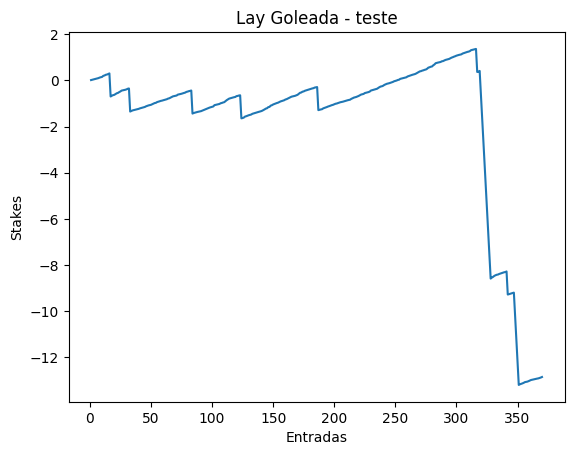

In [29]:
plot_profit_acu(df0, 'Lay Goleada - teste')

Metodo: Lay Away
Profit: 1.04 stakes em 216 jogos
ROI: 0.48 %
Drawdown Maximo Acumulado: -2.56
Winrate Medio: 93.06 %
Desvio Padrao: 0.28



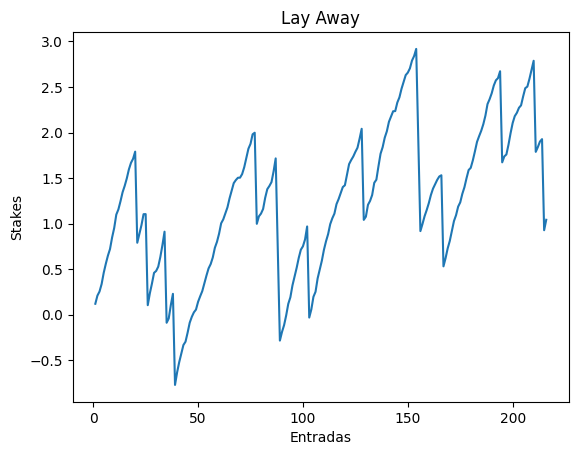

In [18]:
plot_profit_acu(df0, 'Lay Away - Teste')

### Risco de Ruína

In [11]:
# import statistics

# Stake = 0.5
# df0['Profit2'] = Stake * df0['Profit']

# partes = np.array_split(df0, 10)
# df1, df2, df3, df4, df5, df6, df7, df8, df9, df10 = partes

# media_1 = df1['Profit2'].mean()
# media_2 = df2['Profit2'].mean()
# media_3 = df3['Profit2'].mean()
# media_4 = df4['Profit2'].mean()
# media_5 = df5['Profit2'].mean()
# media_6 = df6['Profit2'].mean()
# media_7 = df7['Profit2'].mean()
# media_8 = df8['Profit2'].mean()
# media_9 = df9['Profit2'].mean()
# media_10 = df10['Profit2'].mean()

# lista_medias = [media_1, media_2, media_3, media_4, media_5, media_6, media_7, media_8, media_9, media_10]

# media = statistics.mean(lista_medias)
# desvio_padrao = statistics.stdev(lista_medias)

# banca = 1

# risco_ruina = (np.exp((-2 * media * banca) / (desvio_padrao ** 2))) * 100
# print(f'O Risco de Ruína dessa estratégia é de {round(risco_ruina,2)}%')

### Entradas

In [12]:
# dia = '2024-04-28'
# Jogos_do_Dia = pd.read_csv(f"https://github.com/futpythontrader/YouTube/raw/main/Jogos_do_Dia_FlashScore/{dia}_Jogos_do_Dia_FlashScore.csv")

# flt =
# Entradas = Jogos_do_Dia[flt]
# Entradas = drop_reset_index(Entradas)
# Entradas[['Date','Time','League','Home','Away']]